# 3.1 · Licitaciones: agrupación por código externo y evaluación temporal

Versión independiente de `3.0 Licitaciones_matias.ipynb`. Lee el mismo Feather; no modifica los notebooks 1, 2 ni 3.0.

Cambios: usar `CodigoExterno` para agrupar las compras; conservar los códigos de producto sin convertirlos a `float32`; construir el historial de entrenamiento solo con meses anteriores; verificar que una licitación no cruce particiones; elegir modelo y umbral en validación y evaluar después en test. La base de referencia conserva las agrupaciones aproximadas del profesor y se vuelve a entrenar sobre las mismas filas.

**Alcance:** comparar precios rivales supone que las ofertas ya están disponibles. Esta evaluación retrospectiva no representa una predicción antes del cierre. El historial usa resultados finales y fecha de publicación: sin fecha efectiva de adjudicación, no demuestra que cada etiqueta histórica se conociera a tiempo. Se mantiene como variante experimental. `CodigoExterno` identifica la licitación, pero falta el identificador original de línea y de oferta/proveedor.

In [1]:
from pathlib import Path
import json
import platform
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.metrics import (precision_recall_curve, precision_score, recall_score,
                             f1_score, accuracy_score, roc_auc_score,
                             average_precision_score, ConfusionMatrixDisplay)
from threadpoolctl import threadpool_limits

SEMILLA = 42
ANIO = 2024
ITERACIONES = 200  # mismo presupuesto para los tres modelos de árboles
ENTRENAR_RED = True
# Se conserva la deduplicación de 3.0 para comparar sobre la misma población.
# No demuestra que sean ofertas duplicadas: faltan proveedor e ID de oferta/línea.
QUITAR_DUPLICADOS_HEREDADOS = True
PRIOR_SIN_HISTORIA = 0.5  # constante; no consulta etiquetas futuras
SUAVIZADO = 20
HILOS = 4

CARPETA = Path.cwd()
if not (CARPETA / 'LICIT_depurando_sinNulos.feather').exists():
    CARPETA = CARPETA / 'V0.5 (MM)'
RUTA_DATOS = CARPETA / 'LICIT_depurando_sinNulos.feather'
RUTA_RESULTADOS = CARPETA / 'resultados_3_1'
print('Datos:', RUTA_DATOS.resolve())
print('Python:', platform.python_version(), '| pandas:', pd.__version__, '| sklearn:', sklearn.__version__)

Datos: D:\Licit\1\ML-SmartBids\V0.5 (MM)\LICIT_depurando_sinNulos.feather
Python: 3.12.13 | pandas: 2.3.3 | sklearn: 1.9.1


## Datos y controles

Se informa la eliminación de filas repetidas antes de reproducir la decisión de 3.0. Si distintas ofertas comparten todas las columnas retenidas, esa deduplicación puede eliminarlas: resolverlo requiere recuperar las claves originales desde los CSV. No se deduplica por `CodigoExterno`, porque una licitación contiene muchas ofertas.

Se excluyen completas las licitaciones con más de un año/mes de publicación registrado. Así ninguna licitación puede entrar en entrenamiento y validación/test a la vez. Los cortes incluyen año, no solo número de mes.

In [2]:
df = pd.read_feather(RUTA_DATOS)
requeridas = {'CodigoExterno', 'CodigoUnidad', 'CodigoProductoONU', 'Cantidad',
              'Cantidad Ofertada', 'Valor Total Ofertado', 'MontoEstimado',
              'NumeroOferentes', 'AnioPublicacion', 'MesPublicacion',
              'DiaSemanaPublicacion', 'Seleccionada'}
faltantes = requeridas - set(df.columns)
if faltantes:
    raise KeyError(f'Faltan columnas: {sorted(faltantes)}. Ejecutar primero notebooks 1 y 2.')
if df[list(requeridas)].isna().any().any():
    raise ValueError('Hay claves, fechas, cantidades o etiquetas nulas en las columnas requeridas.')
if df['CodigoExterno'].astype('string').str.strip().eq('').any():
    raise ValueError('Hay códigos externos vacíos.')
if not set(df['Seleccionada'].unique()).issubset({0, 1}):
    raise ValueError('Seleccionada debe ser binaria.')
if not df['MesPublicacion'].between(1, 12).all():
    raise ValueError('Mes de publicación inválido.')

filas_originales = len(df)
duplicados = int(df.duplicated().sum())
if QUITAR_DUPLICADOS_HEREDADOS:
    df = df.drop_duplicates().copy()
filas_tras_deduplicar = len(df)
periodo = df['AnioPublicacion'].astype('int64') * 100 + df['MesPublicacion'].astype('int64')
periodos_por_licitacion = periodo.groupby(df['CodigoExterno'], observed=True).nunique()
codigos_ambiguos = periodos_por_licitacion.index[periodos_por_licitacion.gt(1)]
filas_ambiguas = int(df['CodigoExterno'].isin(codigos_ambiguos).sum())
df = df.loc[~df['CodigoExterno'].isin(codigos_ambiguos)].reset_index(drop=True)
if not df['AnioPublicacion'].eq(ANIO).all():
    raise ValueError(f'Esta comparación requiere únicamente el año {ANIO}. Revisar los cortes antes de continuar.')

auditoria_datos = {
    'filas_originales': filas_originales,
    'duplicados_completos_detectados': duplicados,
    'quitar_duplicados_heredados': QUITAR_DUPLICADOS_HEREDADOS,
    'filas_tras_deduplicar': filas_tras_deduplicar,
    'licitaciones_con_periodo_ambiguo_excluidas': len(codigos_ambiguos),
    'filas_con_periodo_ambiguo_excluidas': filas_ambiguas,
    'filas_modeladas': len(df),
    'licitaciones_modeladas': int(df['CodigoExterno'].nunique()),
}
display(pd.Series(auditoria_datos, name='Auditoría'))

filas_originales                              2248494
duplicados_completos_detectados                360769
quitar_duplicados_heredados                      True
filas_tras_deduplicar                         1887725
licitaciones_con_periodo_ambiguo_excluidas          1
filas_con_periodo_ambiguo_excluidas                 4
filas_modeladas                               1887721
licitaciones_modeladas                         136042
Name: Auditoría, dtype: object

## Cuánto mezclaban las agrupaciones anteriores

La agrupación antigua utiliza comprador, año, mes, día de semana, presupuesto y número de oferentes. Dos licitaciones distintas pueden coincidir en todos esos valores. Se cuenta cuántas filas quedan en grupos que contienen más de un `CodigoExterno`.

In [3]:
compra_aproximada = ['CodigoUnidad', 'AnioPublicacion', 'MesPublicacion',
                     'DiaSemanaPublicacion', 'MontoEstimado', 'NumeroOferentes']
linea_aproximada = compra_aproximada + ['CodigoProductoONU', 'Cantidad']
mezclas = []
for nombre, claves_grupo in [('Compra anterior', compra_aproximada), ('Línea anterior', linea_aproximada)]:
    grupos = df.groupby(claves_grupo, observed=True, dropna=False)['CodigoExterno']
    numero_codigos = grupos.nunique()
    afectadas = grupos.transform('nunique').gt(1)
    mezclas.append({'Agrupación': nombre, 'Grupos': len(numero_codigos),
                    'Grupos con varias licitaciones': int(numero_codigos.gt(1).sum()),
                    'Filas afectadas': int(afectadas.sum()),
                    'Porcentaje de filas': float(100 * afectadas.mean())})
auditoria_grupos = pd.DataFrame(mezclas)
display(auditoria_grupos)

productos = df['CodigoProductoONU'].drop_duplicates()
auditoria_precision = {
    'productos_originales': int(productos.nunique()),
    'productos_si_se_convirtieran_a_float32': int(productos.astype('float32').nunique()),
    'codigos_que_float32_alteraria': int(productos.ne(productos.astype('float32').astype('float64')).sum()),
}
display(pd.Series(auditoria_precision, name='Precisión de códigos'))

,Agrupación,Grupos,Grupos con varias licitaciones,Filas afectadas,Porcentaje de filas
0,Compra anterior,132883,2869,142879,7.568862
1,Línea anterior,364906,9211,126598,6.706394


productos_originales                      11033
productos_si_se_convirtieran_a_float32     5828
codigos_que_float32_alteraria              7732
Name: Precisión de códigos, dtype: int64

## Variables: referencia y agrupación corregida

`Referencia` reproduce las variables del boosting base de 3.0. `CodigoExterno` reemplaza la clave aproximada de compra en el segundo modelo. No se entrega el código externo como número o categoría predictora: se usa para delimitar competidores.

Para comparar productos dentro de una licitación se usa **`CodigoExterno` + `CodigoProductoONU` + `Cantidad`**. Es una aproximación a la línea: todavía puede unir líneas distintas del mismo producto y cantidad. Para resolverlo hay que conservar un ID de línea verificado desde el origen. Tampoco se puede asegurar que el presupuesto de toda la licitación corresponda al presupuesto de cada línea.

In [4]:
columnas = ['MontoEstimado', 'NumeroOferentes', 'Cantidad', 'Cantidad Ofertada',
            'Valor Total Ofertado', 'CodigoProductoONU', 'DiaSemanaPublicacion']
indicadores = df.filter(regex='^(sector_|Tipo_|Region_)').columns.tolist()
y = df['Seleccionada'].astype('int8')
cantidad = df['Cantidad Ofertada']
precio = df['Valor Total Ofertado'].where(df['Valor Total Ofertado'] > 0)
unitario = precio / cantidad.where(cantidad > 0)

def division_segura(numerador, denominador):
    return (numerador / denominador.where(denominador > 0)).replace([np.inf, -np.inf], np.nan)

def variables(compra, linea):
    resultado = df[columnas + indicadores].copy()
    resultado['precio_unitario'] = unitario
    resultado['fraccion_cantidad'] = division_segura(cantidad, df['Cantidad'])
    resultado['oferta_sobre_presupuesto'] = division_segura(precio, df['MontoEstimado'])
    temporal = df.assign(_unitario=unitario)
    precios_grupo = temporal.groupby(linea, sort=False, observed=True)['_unitario']
    resultado['precio_sobre_minimo'] = division_segura(unitario, precios_grupo.transform('min'))
    resultado['precio_sobre_mediana'] = division_segura(unitario, precios_grupo.transform('median'))
    resultado['puesto_relativo_precio'] = precios_grupo.rank(method='min', pct=True)
    resultado['ofertas_con_precio'] = precios_grupo.transform('count')
    grupos = temporal.groupby(compra, sort=False, observed=True)
    resultado['productos_en_proceso'] = grupos['CodigoProductoONU'].transform('nunique')
    resultado['filas_en_proceso'] = grupos['Cantidad'].transform('size')
    resultado['ofertas_por_producto'] = division_segura(resultado['filas_en_proceso'], resultado['productos_en_proceso'])
    resultado['proporcion_precio_valido'] = division_segura(resultado['ofertas_con_precio'], precios_grupo.transform('size'))
    resultado['unidad_compradora'] = df['CodigoUnidad']
    assert np.array_equal(resultado['CodigoProductoONU'].to_numpy(), df['CodigoProductoONU'].to_numpy())
    return resultado.replace([np.inf, -np.inf], np.nan)

X_referencia = variables(compra_aproximada, linea_aproximada)
X_codigo = variables(['CodigoExterno'], ['CodigoExterno', 'CodigoProductoONU', 'Cantidad'])
print('Variables por modelo:', X_codigo.shape[1])
print('CodigoProductoONU conserva el tipo:', X_codigo['CodigoProductoONU'].dtype)
print('NaN derivados permitidos: HGB los maneja y la red los imputa con entrenamiento.')

Variables por modelo: 55
CodigoProductoONU conserva el tipo: int32
NaN derivados permitidos: HGB los maneja y la red los imputa con entrenamiento.


## Particiones temporales completas por licitación

Entrenamiento: enero–agosto de 2024. Validación: septiembre–octubre. Test: noviembre–diciembre. Las comparaciones de precios solo consultan ofertas de la misma partición; todas las ofertas de cada licitación permanecen juntas. Las variables requieren conocer las ofertas competidoras al momento de uso.

In [5]:
mes = df['MesPublicacion']
train = df['AnioPublicacion'].eq(ANIO) & mes.between(1, 8)
val = df['AnioPublicacion'].eq(ANIO) & mes.between(9, 10)
test = df['AnioPublicacion'].eq(ANIO) & mes.between(11, 12)
indices = {'Train': df.index[train], 'Validación': df.index[val], 'Test': df.index[test]}
assert (train.astype('int8') + val.astype('int8') + test.astype('int8')).eq(1).all()
ids = {nombre: set(df.loc[idx, 'CodigoExterno']) for nombre, idx in indices.items()}
assert not (ids['Train'] & ids['Validación'] or ids['Train'] & ids['Test'] or ids['Validación'] & ids['Test'])
for nombre, idx in indices.items():
    if len(idx) == 0 or y.loc[idx].nunique() != 2:
        raise ValueError(f'{nombre} no tiene datos suficientes de las dos clases.')

display(pd.DataFrame([
    {'Partición': nombre, 'Filas': len(idx), 'Licitaciones': len(ids[nombre]),
     'Tasa seleccionada': float(y.loc[idx].mean())}
    for nombre, idx in indices.items()
]))
idx_train, idx_val, idx_test = indices.values()

,Partición,Filas,Licitaciones,Tasa seleccionada
0,Train,1373553,96114,0.175666
1,Validación,228766,19337,0.107743
2,Test,285402,20591,0.199613


## Historial experimental: únicamente meses anteriores

Se elimina la división `mes % 4`, que permitía construir variables de enero con resultados de meses posteriores. Cada mes de entrenamiento consulta solo meses estrictamente anteriores. Enero recibe una constante fijada sin consultar etiquetas y conteo cero. Validación y test consultan exclusivamente entrenamiento, con el historial congelado al terminar agosto.

Se conserva el precio redondeado y el suavizado de 3.0. Se añaden conteos de antecedentes para distinguir una tasa observada de un grupo nuevo. **Esto corrige la dirección de publicación, pero falta verificar cuándo se conoció cada adjudicación.** No se usa el historial para sostener disponibilidad real anterior al cierre.

In [6]:
claves_historia = pd.DataFrame({'unidad': df['CodigoUnidad'],
                               'producto': df['CodigoProductoONU'],
                               'precio': unitario.round()})
GRUPOS_HISTORIA = [['unidad'], ['producto'], ['unidad', 'producto'],
                  ['producto', 'precio'], ['unidad', 'producto', 'precio']]

def historial(pasado, destino):
    if len(set(pasado).intersection(destino)):
        raise ValueError('Una fila consulta su propia etiqueta.')
    if len(pasado) and len(destino) and mes.loc[pasado].max() >= mes.loc[destino].min():
        raise ValueError('El historial contiene meses contemporáneos o futuros.')
    datos = claves_historia.loc[pasado].assign(seleccion=y.loc[pasado])
    promedio = float(datos['seleccion'].mean()) if len(datos) else PRIOR_SIN_HISTORIA
    resultado = pd.DataFrame(index=destino)
    for grupo in GRUPOS_HISTORIA:
        nombre = '_'.join(grupo)
        if datos.empty:
            resultado['hist_' + nombre] = promedio
            resultado['antecedentes_' + nombre] = 0.0
            continue
        conteo = datos.groupby(grupo, observed=True)['seleccion'].agg(['sum', 'count'])
        tasa = (conteo['sum'] + SUAVIZADO * promedio) / (conteo['count'] + SUAVIZADO)
        consultas = claves_historia.loc[destino]
        resultado['hist_' + nombre] = consultas.join(tasa.rename('_tasa'), on=grupo)['_tasa'].fillna(promedio)
        resultado['antecedentes_' + nombre] = consultas.join(conteo['count'].rename('_n'), on=grupo)['_n'].fillna(0)
    return resultado

partes = []
registro_historia = []
for numero_mes in sorted(mes.loc[idx_train].unique()):
    pasado = df.index[train & mes.lt(numero_mes)]
    destino = df.index[train & mes.eq(numero_mes)]
    partes.append(historial(pasado, destino))
    registro_historia.append({'mes_destino': int(numero_mes), 'filas_pasadas': len(pasado),
                              'filas_destino': len(destino),
                              'ultimo_mes_consultado': int(mes.loc[pasado].max()) if len(pasado) else None})
hist_train = pd.concat(partes).reindex(idx_train)
hist_val = historial(idx_train, idx_val)
hist_test = historial(idx_train, idx_test)
X_train_hist = X_codigo.loc[idx_train].join(hist_train)
X_val_hist = X_codigo.loc[idx_val].join(hist_val)
X_test_hist = X_codigo.loc[idx_test].join(hist_test)
assert not hist_train.isna().any().any()
assert X_train_hist['CodigoProductoONU'].equals(df.loc[idx_train, 'CodigoProductoONU'])
display(pd.DataFrame(registro_historia))

,mes_destino,filas_pasadas,filas_destino,ultimo_mes_consultado
0,1,0,178662,NaN
1,2,178662,189468,1.0
2,3,368130,193182,2.0
3,4,561312,221356,3.0
4,5,782668,173773,4.0
5,6,956441,109151,5.0
6,7,1065592,178553,6.0
7,8,1244145,129408,7.0


## Entrenar los modelos

Los tres modelos de árboles usan los mismos hiperparámetros y 200 iteraciones para comparar sus variables. La red mantiene las capas 64/32 y el máximo de 350.000 filas de 3.0. Su validación interna para parada temprana es aleatoria dentro de entrenamiento: no es el test temporal externo. No se convierten las matrices a `float32`; así los códigos de ocho dígitos se conservan exactamente en la entrada.

In [7]:
def boosting():
    return HistGradientBoostingClassifier(max_iter=ITERACIONES, early_stopping=False,
                                           random_state=SEMILLA)

modelos = {}
with threadpool_limits(limits=HILOS):
    for nombre, matriz in [('Referencia', X_referencia.loc[idx_train]),
                           ('CodigoExterno', X_codigo.loc[idx_train]),
                           ('Historial experimental', X_train_hist)]:
        print('Entrenando:', nombre, flush=True)
        modelos[nombre] = boosting().fit(matriz, y.loc[idx_train])
    if ENTRENAR_RED:
        print('Entrenando: Red experimental', flush=True)
        muestra = X_train_hist.sample(n=min(350000, len(X_train_hist)), random_state=SEMILLA)
        modelos['Red experimental'] = make_pipeline(
            SimpleImputer(strategy='median', add_indicator=True),
            QuantileTransformer(n_quantiles=128, subsample=30000, random_state=SEMILLA),
            MLPClassifier(hidden_layer_sizes=(64, 32), batch_size=512, early_stopping=True,
                          max_iter=45, n_iter_no_change=5, random_state=SEMILLA)
        ).fit(muestra, y.loc[muestra.index])
print('Entrenamiento terminado.')

Entrenando: Referencia


Entrenando: CodigoExterno


Entrenando: Historial experimental


Entrenando: Red experimental


Entrenamiento terminado.


## Elegir en validación; evaluar test una vez

Cada modelo elige el umbral de mayor F1 en validación. El ensamble mantiene pesos prefijados de 3.0: 25 % código externo, 50 % historial y 25 % red. También se elige el mejor candidato sin historial experimental entre `Referencia` y `CodigoExterno`. Las métricas de test no intervienen en esas decisiones. Average precision acompaña a F1 y ROC AUC por el desbalance de clases.

In [8]:
def puntajes(idx, matriz_hist):
    matrices = {'Referencia': X_referencia.loc[idx],
                'CodigoExterno': X_codigo.loc[idx],
                'Historial experimental': matriz_hist,
                'Red experimental': matriz_hist}
    p = pd.DataFrame(index=idx)
    with threadpool_limits(limits=HILOS):
        for nombre, modelo in modelos.items():
            p[nombre] = modelo.predict_proba(matrices[nombre])[:, 1]
    if ENTRENAR_RED:
        p['Ensamble experimental'] = (0.25 * p['CodigoExterno']
                                      + 0.50 * p['Historial experimental']
                                      + 0.25 * p['Red experimental'])
    if not np.isfinite(p.to_numpy()).all():
        raise ValueError('Hay puntajes inválidos.')
    return p

def metricas(etiquetas, probabilidades, umbral):
    pred = probabilidades >= umbral
    return {'Umbral': float(umbral), 'Precisión': precision_score(etiquetas, pred, zero_division=0),
            'Recall': recall_score(etiquetas, pred, zero_division=0),
            'F1': f1_score(etiquetas, pred, zero_division=0),
            'Accuracy': accuracy_score(etiquetas, pred),
            'ROC-AUC': roc_auc_score(etiquetas, probabilidades),
            'Average precision': average_precision_score(etiquetas, probabilidades),
            'Alertas': int(pred.sum())}

p_val = puntajes(idx_val, X_val_hist)
umbrales = {}
for nombre in p_val:
    precision, recall, cortes = precision_recall_curve(y.loc[idx_val], p_val[nombre])
    valores_f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    umbrales[nombre] = float(cortes[np.argmax(valores_f1)])
validacion = pd.DataFrame({n: metricas(y.loc[idx_val], p_val[n], umbrales[n]) for n in p_val}).T
validacion.index.name = 'Modelo'
elegido = validacion['F1'].idxmax()
elegido_sin_historial = validacion.loc[['Referencia', 'CodigoExterno'], 'F1'].idxmax()
print('Elegido por F1 de validación, incluyendo variantes experimentales:', elegido)
print('Elegido sin historial experimental:', elegido_sin_historial)
display(validacion.round(4))

# Las decisiones anteriores quedan fijadas antes de consultar las métricas de test.
p_test = puntajes(idx_test, X_test_hist)
resultados = pd.DataFrame({n: metricas(y.loc[idx_test], p_test[n], umbrales[n]) for n in p_test}).T
resultados.index.name = 'Modelo'
resultados['Delta F1 vs referencia'] = resultados['F1'] - resultados.loc['Referencia', 'F1']
print('TEST: noviembre–diciembre, umbrales fijados en validación')
display(resultados.round(4))
print('Accuracy de predecir siempre No:', round(float(1 - y.loc[idx_test].mean()), 4))
print('Average precision de referencia aleatoria (prevalencia):', round(float(y.loc[idx_test].mean()), 4))

Elegido por F1 de validación, incluyendo variantes experimentales: Ensamble experimental
Elegido sin historial experimental: Referencia


,Umbral,Precisión,Recall,F1,Accuracy,ROC-AUC,Average precision,Alertas
Modelo,,,,,,,,
Referencia,0.3175,0.3267,0.5204,0.4014,0.8328,0.8041,0.3488,39257.0
CodigoExterno,0.2933,0.3107,0.5633,0.4005,0.8183,0.8029,0.3516,44689.0
Historial experimental,0.1982,0.3406,0.5438,0.4189,0.8374,0.8188,0.3809,39351.0
Red experimental,0.2151,0.3393,0.5153,0.4092,0.8396,0.8088,0.3626,37440.0
Ensamble experimental,0.2318,0.3455,0.5452,0.4229,0.8397,0.8190,0.3872,38899.0


TEST: noviembre–diciembre, umbrales fijados en validación


,Umbral,Precisión,Recall,F1,Accuracy,ROC-AUC,Average precision,Alertas,Delta F1 vs referencia
Modelo,,,,,,,,,
Referencia,0.3175,0.5269,0.4298,0.4734,0.8091,0.7825,0.4944,46471.0,0.0000
CodigoExterno,0.2933,0.5033,0.4722,0.4873,0.8016,0.7829,0.4934,53452.0,0.0138
Historial experimental,0.1982,0.5011,0.3605,0.4193,0.8007,0.7386,0.4516,40981.0,-0.0541
Red experimental,0.2151,0.4920,0.3507,0.4095,0.7981,0.7143,0.4291,40606.0,-0.0639
Ensamble experimental,0.2318,0.5221,0.3848,0.4430,0.8069,0.7658,0.4769,41987.0,-0.0304


Accuracy de predecir siempre No: 0.8004
Average precision de referencia aleatoria (prevalencia): 0.1996


## Estabilidad por mes y errores

Los resultados mensuales usan los mismos umbrales. La matriz corresponde al candidato elegido en validación; si se eligió una variante experimental, mantiene las limitaciones del historial descritas arriba.

,Mes,Modelo,Filas,Tasa seleccionada,Umbral,Precisión,Recall,F1,Accuracy,ROC-AUC,Average precision,Alertas
0,11,Referencia,188346,0.2032,0.3175,0.5277,0.4183,0.4667,0.8058,0.7733,0.4825,30329
1,11,CodigoExterno,188346,0.2032,0.2933,0.5060,0.4649,0.4846,0.7991,0.7753,0.4863,35157
2,11,Historial experimental,188346,0.2032,0.1982,0.4987,0.3649,0.4214,0.7964,0.7318,0.4455,27998
3,11,Red experimental,188346,0.2032,0.2151,0.4909,0.3573,0.4136,0.7942,0.7120,0.4279,27851
4,11,Ensamble experimental,188346,0.2032,0.2318,0.5202,0.3841,0.4419,0.8029,0.7579,0.4692,28255
5,12,Referencia,97056,0.1927,0.3175,0.5254,0.4534,0.4868,0.8157,0.8008,0.5208,16142
6,12,CodigoExterno,97056,0.1927,0.2933,0.4981,0.4872,0.4926,0.8066,0.7981,0.5137,18295
7,12,Historial experimental,97056,0.1927,0.1982,0.5063,0.3514,0.4149,0.8090,0.7524,0.4640,12983
8,12,Red experimental,97056,0.1927,0.2151,0.4944,0.3371,0.4009,0.8058,0.7198,0.4314,12755
9,12,Ensamble experimental,97056,0.1927,0.2318,0.5261,0.3862,0.4454,0.8147,0.7815,0.4928,13732


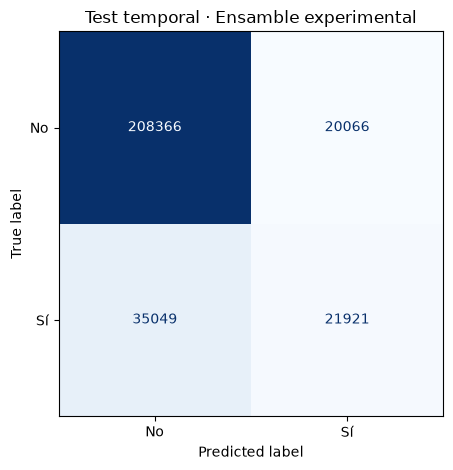

Ganadoras omitidas por el candidato elegido: 61.5%


In [9]:
mensuales = []
for numero_mes in (11, 12):
    idx = idx_test[mes.loc[idx_test].eq(numero_mes)]
    for nombre in p_test:
        mensuales.append({'Mes': numero_mes, 'Modelo': nombre, 'Filas': len(idx),
                          'Tasa seleccionada': float(y.loc[idx].mean()),
                          **metricas(y.loc[idx], p_test.loc[idx, nombre], umbrales[nombre])})
por_mes = pd.DataFrame(mensuales)
display(por_mes.round(4))
ConfusionMatrixDisplay.from_predictions(
    y.loc[idx_test], p_test[elegido] >= umbrales[elegido],
    display_labels=['No', 'Sí'], cmap='Blues', colorbar=False, values_format='d')
plt.title(f'Test temporal · {elegido}')
plt.tight_layout()
plt.show()

ganadoras = y.loc[idx_test].eq(1)
predicciones = p_test.ge(pd.Series(umbrales), axis='columns')
print('Ganadoras omitidas por el candidato elegido:',
      f'{(~predicciones.loc[ganadoras, elegido]).mean():.1%}')

## Guardar resultados y límites de la comparación

Se guardan tablas, configuración, auditoría y huella del Feather. No se sobrescriben resultados de otras versiones. `resultados_3_1` contiene la última ejecución de este notebook. No se declara una mejora solo porque cambió la agrupación: se muestra la diferencia observada contra la referencia entrenada en esta misma ejecución.

La exclusión de licitaciones con publicación inconsistente y los ajustes de entrenamiento hacen que las cifras puedan diferir de las salidas guardadas de 3.0. Todo 2024 ya se exploró en otras versiones: este test es retrospectivo y no constituye una confirmación independiente. Para uso antes del cierre deben excluirse variables que requieren conocer a los rivales; para historial real hacen falta fechas de resultados disponibles y claves verificadas de línea, oferta y proveedor.

In [10]:
RUTA_RESULTADOS.mkdir(exist_ok=True)
validacion.to_csv(RUTA_RESULTADOS / 'validacion.csv', encoding='utf-8-sig')
resultados.to_csv(RUTA_RESULTADOS / 'test.csv', encoding='utf-8-sig')
por_mes.to_csv(RUTA_RESULTADOS / 'test_por_mes.csv', index=False, encoding='utf-8-sig')
auditoria_grupos.to_csv(RUTA_RESULTADOS / 'auditoria_grupos.csv', index=False, encoding='utf-8-sig')
configuracion = {
    'semilla': SEMILLA, 'anio': ANIO, 'iteraciones_boosting': ITERACIONES,
    'entrenar_red': ENTRENAR_RED, 'suavizado': SUAVIZADO,
    'prior_sin_historia': PRIOR_SIN_HISTORIA, 'hilos': HILOS,
    'datos_sha256': hashlib.sha256(RUTA_DATOS.read_bytes()).hexdigest(),
    'python': platform.python_version(), 'pandas': pd.__version__, 'sklearn': sklearn.__version__,
    'auditoria_datos': auditoria_datos, 'auditoria_precision': auditoria_precision,
    'registro_historia': registro_historia,
    'elegido_validacion_incluye_experimentales': elegido,
    'elegido_validacion_sin_historial': elegido_sin_historial,
    'umbrales': umbrales,
    'limitaciones': ['Sin ID original de línea/oferta/proveedor',
                    'Deduplicación heredada sin verificar identidad de oferta',
                    'Precios rivales disponibles solo después de recibir ofertas',
                    'Historial sin fecha efectiva de disponibilidad del resultado',
                    'Test 2024 explorado previamente; no es confirmación independiente'],
}
(RUTA_RESULTADOS / 'configuracion.json').write_text(
    json.dumps(configuracion, ensure_ascii=False, indent=2), encoding='utf-8')
f1_base = resultados.loc['Referencia', 'F1']
f1_codigo = resultados.loc['CodigoExterno', 'F1']
print(f'F1 referencia: {f1_base:.4f} | Código externo: {f1_codigo:.4f}')
print(f'Diferencia observada al corregir grupos: {100 * (f1_codigo - f1_base):+.2f} puntos de F1.')
print('Sin una estimación de incertidumbre no se declara significancia de esa diferencia.')
print('Resultados:', RUTA_RESULTADOS.resolve())

F1 referencia: 0.4734 | Código externo: 0.4873
Diferencia observada al corregir grupos: +1.38 puntos de F1.
Sin una estimación de incertidumbre no se declara significancia de esa diferencia.
Resultados: D:\Licit\1\ML-SmartBids\V0.5 (MM)\resultados_3_1


## Lectura de esta ejecución

La referencia obtuvo F1 **0,4734** y el modelo con `CodigoExterno`, **0,4873** (diferencia observada de **+1,38 puntos porcentuales**). El historial obtuvo **0,4193**, la red **0,4095** y el ensamble **0,4430**.

El ensamble fue elegido por F1 en validación, pero perdió rendimiento en test. Entre las dos alternativas sin historial, validación eligió la referencia por un margen pequeño. Por eso, el mejor F1 observado del código externo en test no se usa para cambiar retrospectivamente la selección. ROC AUC y average precision son muy similares entre referencia y código externo: no hay evidencia de una mejora amplia del ordenamiento de ofertas.

La agrupación corregida evita mezclar licitaciones y merece conservarse por integridad de los datos. Esta prueba no confirma una mejora futura ni respalda añadir el historial o el ensamble.